# Расчётно-графическая работа

## Применение искусственного интеллекта в образовании

**Дисциплина:** Системы искусственного интеллекта и машинное обучение

**Вариант № 5.** Обработка естественного языка (NLP)

## 1. Введение

### Цель работы

Исследование современных направлений применения искусственного интеллекта в образовании с помощью методов обработки естественного языка и машинного обучения на основе научных публикаций.

### Задачи работы

1. Изучить источник публикаций и реализовать получение данных через HTTP-запросы.
2. Сформировать корпус текстов, сохранить данные и исследовать их характеристики.
3. Выполнить очистку, токенизацию, удаление стоп-слов, стемминг и лемматизацию.
4. Рассчитать частоты ключевых терминов и визуализировать результаты.
5. Выделить наиболее значимые слова и выражения с помощью TF-IDF.
6. Реализовать классификацию методом Naive Bayes, сравнить варианты представления текста и оценить качество модели.
7. Проанализировать полученные результаты и сформулировать выводы о применении ИИ в образовании.

Объект исследования — научные публикации об ИИ в образовании. Предмет исследования — их терминологические и тематические характеристики.

### Обзор методов решения

Частотный анализ и мешок слов (CountVectorizer) позволяют оценить распространённость лексики, но не учитывают её контекст. TF-IDF уменьшает вес общих слов и выделяет характерные признаки документов; биграммы частично учитывают порядок слов. Multinomial Naive Bayes подходит для небольших текстовых выборок и позволяет оценить качество тематической классификации при умеренных вычислительных затратах. Более сложные методы на основе эмбеддингов и трансформеров могут учитывать контекст лучше, однако требуют отдельной проверки. В данной работе выбраны частотные методы, TF-IDF и Naive Bayes в соответствии с заданием.

## 2. Получение и характеристика исходных данных

### 2.1. Источник публикаций

Индивидуальный вариант указывает издание **EdSurge**, однако его условия ограничивают автоматизированный сбор и использование материалов для машинного обучения без разрешения. Поэтому для количественного эксперимента выбран **OpenAlex**, предоставляющий научные метаданные.

Отобраны англоязычные статьи об ИИ в образовании за период **24.11.2025–23.11.2026** по подполю *Education*, типу *article* и доступности аннотации. Исходный ответ API содержит 200 записей; после проверки содержания и исключения нерелевантных или пересекающихся материалов корпус составил **131 публикацию**. Отбор исходного ответа по убыванию цитируемости может смещать выборку к более ранним работам.

### 2.2. Описание данных

Каждая строка корпуса соответствует одной научной публикации. Для анализа используются следующие поля:

| Признак | Описание |
|---|---|
| `id` | Идентификатор публикации в OpenAlex |
| `title` | Заголовок |
| `abstract` | Аннотация |
| `text` | Заголовок и аннотация, объединённые для анализа |
| `publication_date` | Дата публикации |
| `source_name` | Название журнала или другого источника |
| `authors`, `url` | Авторы и ссылка на публикацию |
| `text_license` | Лицензия по сведениям OpenAlex |
| `label` | Основная тематическая категория |
| `annotation_rationale` | Обоснование тематической метки |

Метка `label` используется только при обучении и оценке классификатора; авторы, ссылки и обоснования меток не входят в текстовые признаки.

### 2.3. Загрузка датасета

Загрузим сохранённый JSON-корпус, исходный ответ OpenAlex и сведения о выполненном запросе. Выведем размеры набора и несколько примеров публикаций.

In [1]:
from pathlib import Path
import json
import hashlib
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Исходные публикации и журнал обращения к API.
ROOT = Path.cwd()
DATA = ROOT / "data"

with (DATA / "corpus.json").open(encoding="utf-8") as file:
    records = json.load(file)
with (DATA / "requests.json").open(encoding="utf-8") as file:
    request_log = json.load(file)
raw_response = (DATA / "openalex_original.json").read_bytes()

articles = pd.DataFrame(records)
print("Записей в ответе OpenAlex:", len(json.loads(raw_response)["results"]))
print("Статей в исследуемом корпусе:", len(articles))
print("Количество источников:", articles["source_name"].nunique())
display(articles[["publication_date", "title", "source_name"]].head(4))

Записей в ответе OpenAlex: 200
Статей в исследуемом корпусе: 131
Количество источников: 68


,publication_date,title,source_name
0,2026-01-06,The impact of generative AI on academic readin...,Frontiers in Education
1,2026-01-06,The AI literacy heptagon: A structured approac...,Computers and Education Artificial Intelligence
2,2025-12-02,The role of over-reliance on AI in the negativ...,Cogent Education
3,2026-07-17,Agency in the age of generative AI: a critical...,Academia AI and Applications


### 2.4. Первичная проверка качества данных

Проверим количество пропусков в основных полях, пустых текстов и повторяющихся идентификаторов. Контрольная сумма позволяет убедиться, что исходный HTTP-ответ не изменён.

In [2]:
fields = ["id", "title", "abstract", "publication_date", "source_name", "label"]
display(articles[fields].isna().sum().to_frame("Пропущенные значения"))
print("Повторяющихся идентификаторов:", articles["id"].duplicated().sum())
print("Пустых текстов:", articles["text"].fillna("").str.strip().eq("").sum())
print("Диапазон дат:", articles["publication_date"].min(), "—", articles["publication_date"].max())
print("Язык публикаций:", articles["language"].unique())
print("Контрольная сумма исходного ответа совпадает:",
      hashlib.sha256(raw_response).hexdigest() == request_log[0]["sha256"])

,Пропущенные значения
id,0
title,0
abstract,0
publication_date,0
source_name,0
label,0


Повторяющихся идентификаторов: 0
Пустых текстов: 0
Диапазон дат: 2025-11-24 — 2026-10-01
Язык публикаций: ['en']
Контрольная сумма исходного ответа совпадает: True


#### Вывод по первичной проверке

Исходный ответ содержит 200 записей, из которых после содержательного отбора оставлена 131 публикация из 68 источников. Даты итоговых публикаций — с 24.11.2025 по 01.10.2026. В основных полях корпуса отсутствуют пропуски, пустые тексты и повторяющиеся идентификаторы. Контрольная сумма исходного ответа совпадает. Все тексты англоязычные, поэтому далее используются инструменты обработки английского языка.

### 2.5. HTTP-запрос к OpenAlex

Данные можно получить запросом `GET` к `https://api.openalex.org/works` с фильтрами по тематике, языку, периоду публикации и лицензии. Функция ниже демонстрирует получение нового ответа и сохранение его в JSON. При повторном обращении к API состав публикаций может отличаться от сохранённого корпуса, поэтому новая выгрузка **не подменяет** размеченные данные текущего исследования.

In [3]:
import os
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry


def download_openalex(limit=200):
    """Получить новые публикационные метаданные и сохранить ответ API."""
    parameters = dict(request_log[0]["params"])
    parameters["per-page"] = min(limit, 200)
    parameters["page"] = 1
    if os.getenv("OPENALEX_API_KEY"):
        parameters["api_key"] = os.environ["OPENALEX_API_KEY"]

    retries = Retry(total=3, backoff_factor=1,
                    status_forcelist=[429, 500, 502, 503, 504])
    with requests.Session() as session:
        session.mount("https://", HTTPAdapter(max_retries=retries))
        response = session.get("https://api.openalex.org/works",
                               params=parameters, timeout=(15, 90))
        response.raise_for_status()
        payload = response.json()

    if not isinstance(payload.get("results"), list):
        raise ValueError("Ответ API не содержит список results")
    path = DATA / "new_openalex_response.json"
    path.write_bytes(response.content)
    return payload["results"]


# Повторное сетевое обращение необязательно: исходный ответ уже сохранён.
LIVE_HTTP = False
if LIVE_HTTP:
    new_publications = download_openalex()
    print("Получено новых записей:", len(new_publications))
else:
    print("Для исследования используется сохранённый ответ OpenAlex (200 записей).")

Для исследования используется сохранённый ответ OpenAlex (200 записей).


#### Вывод по получению данных

Для сбора публикаций реализовано обращение к OpenAlex Works API с проверкой HTTP-статуса и сохранением ответа в JSON. В исследовании используется фиксированная выгрузка от 23.11.2026. При изменении ответа API потребовалось бы заново проверить тематическую релевантность и разметить новые статьи.

## 3. Предварительная обработка текстов

### 3.1. Очистка текста и токенизация

Обработка естественного языка (NLP) — совокупность методов анализа текстов средствами вычислительных алгоритмов. Для представления текста в виде признаков удалим HTML-разметку, ссылки, адреса электронной почты и посторонние символы. Затем приведём текст к нижнему регистру и разобьём его на токены — отдельные слова и обозначения.

In [4]:
import html
import unicodedata
from functools import lru_cache

import nltk
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

# Загрузка необходимых языковых данных при первом использовании NLTK.
for resource, name in [
    ("corpora/stopwords", "stopwords"),
    ("corpora/wordnet.zip", "wordnet"),
    ("taggers/averaged_perceptron_tagger_eng", "averaged_perceptron_tagger_eng"),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        if not nltk.download(name, quiet=True):
            raise RuntimeError(f"Не найден ресурс NLTK: {name}")

TOKENIZER = RegexpTokenizer(r"[a-z]+(?:[-.]?\d+(?:[.-]\d+)*)?")
PROTECTED = {"ai", "ml", "llm", "llms", "gpt", "chatgpt", "nlp", "dl", "aied", "genai"}

@lru_cache(maxsize=1)
def get_stopwords():
    return set(stopwords.words("english")) - PROTECTED - {"no", "not", "nor"}


def clean_text(text):
    """Удалить разметку и технические элементы текста."""
    text = BeautifulSoup(html.unescape(str(text)), "html.parser").get_text(" ")
    text = unicodedata.normalize("NFKC", text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-z]+\b", " ", text)
    text = re.sub(r"[^a-z0-9\s.\-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text, without_stopwords=True):
    words = TOKENIZER.tokenize(clean_text(text))
    words = [w for w in words if len(w) > 1 or w in PROTECTED]
    return [w for w in words if w not in get_stopwords()] if without_stopwords else words



# Покажем преобразование начала одной аннотации.
sample_text = articles.iloc[0]["text"]
print("Исходный фрагмент:", sample_text[:350])
print("Очищенный фрагмент:", clean_text(sample_text)[:350])
print("Токены:", tokenize(sample_text, without_stopwords=False)[:25])

Исходный фрагмент: The impact of generative AI on academic reading and writing: a synthesis of recent evidence (2023–2025). Introduction The aim of this systematic review is to examine the scientific literature published on digital reading and writing in higher education within the field of social sciences, assisted by generative artificial intelligence. Methods The 
Очищенный фрагмент: the impact of generative ai on academic reading and writing a synthesis of recent evidence 2023 2025 . introduction the aim of this systematic review is to examine the scientific literature published on digital reading and writing in higher education within the field of social sciences assisted by generative artificial intelligence. methods the pri
Токены: ['the', 'impact', 'of', 'generative', 'ai', 'on', 'academic', 'reading', 'and', 'writing', 'synthesis', 'of', 'recent', 'evidence', 'introduction', 'the', 'aim', 'of', 'this', 'systematic', 'review', 'is', 'to', 'examine', 'the']


#### Вывод по очистке и токенизации

Текст представлен последовательностью отдельных слов. Регистр и технические элементы не влияют на дальнейший подсчёт частот; предметные сокращения сохраняются.

### 3.2. Удаление стоп-слов

Стоп-слова — часто встречающиеся служебные слова, например *the*, *of*, *and*. Они обычно не характеризуют тематику документа. Используем английский список NLTK, сохранив специальные сокращения AI, ML, NLP, LLM и отрицания no, not, nor.

In [5]:
tokens_before = tokenize(sample_text, without_stopwords=False)
tokens_after = tokenize(sample_text)
print("До удаления стоп-слов:", tokens_before[:25])
print("После удаления стоп-слов:", tokens_after[:25])
print("Количество токенов до обработки:", len(tokens_before))
print("Количество токенов после обработки:", len(tokens_after))

До удаления стоп-слов: ['the', 'impact', 'of', 'generative', 'ai', 'on', 'academic', 'reading', 'and', 'writing', 'synthesis', 'of', 'recent', 'evidence', 'introduction', 'the', 'aim', 'of', 'this', 'systematic', 'review', 'is', 'to', 'examine', 'the']
После удаления стоп-слов: ['impact', 'generative', 'ai', 'academic', 'reading', 'writing', 'synthesis', 'recent', 'evidence', 'introduction', 'aim', 'systematic', 'review', 'examine', 'scientific', 'literature', 'published', 'digital', 'reading', 'writing', 'higher', 'education', 'within', 'field', 'social']
Количество токенов до обработки: 313
Количество токенов после обработки: 211


#### Вывод по стоп-словам

Удаление служебной лексики сокращает число малосодержательных признаков. Сохранение отрицаний и предметных сокращений уменьшает риск потери значимой информации.

В рассмотренном примере число токенов сократилось с 313 до 211.

### 3.3. Стемминг и лемматизация

Стемминг отсекает части слова по формальным правилам, а лемматизация приводит слово к словарной форме с учётом его части речи. Для первого подхода используем `SnowballStemmer`, для второго — `WordNetLemmatizer` и английский POS-теггер NLTK. Сравним преобразования на примерах слов из корпуса.

In [6]:
STEMMER = SnowballStemmer("english")
LEMMATIZER = WordNetLemmatizer()

def normalize(text, method="lemma"):
    """Получить исходные токены, стемы или леммы."""
    words = tokenize(text, without_stopwords=False)
    tagged = nltk.pos_tag(words, lang="eng") if method == "lemma" else [(w, "") for w in words]
    result = []
    for word, pos in tagged:
        if word in get_stopwords():
            continue
        if word in PROTECTED:
            result.append(word)
        elif method == "lemma":
            wn_pos = {"J": "a", "V": "v", "N": "n", "R": "r"}.get(pos[:1], "n")
            result.append(LEMMATIZER.lemmatize(word, wn_pos))
        elif method == "stem":
            result.append(STEMMER.stem(word))
        elif method == "none":
            result.append(word)
        else:
            raise ValueError(f"Неизвестный способ обработки: {method}")
    return result
examples = ["studies", "students", "teaching", "universities", "educational"]
comparison = pd.DataFrame({
    "Слово": examples,
    "Стемминг": [STEMMER.stem(w) for w in examples],
    "Лемматизация (существительное)": [LEMMATIZER.lemmatize(w, "n") for w in examples]
})
display(comparison)

,Слово,Стемминг,Лемматизация (существительное)
0,studies,studi,study
1,students,student,student
2,teaching,teach,teaching
3,universities,univers,university
4,educational,educ,educational


#### Вывод по нормализации

Стемминг сокращает, например, studies до studi, universities до univers, educational до educ. Лемматизация сохраняет читаемые формы study, university и educational. Поэтому для основного анализа выбраны леммы; при обработке полного текста учитывается часть речи.

### 3.4. Обработка всего корпуса

Применим рассмотренные методы к каждой публикации. Сформируем три текстовых представления: токены без стоп-слов, стемы и леммы. Первое и третье используются при сравнении моделей.

In [7]:
# Каждая строка содержит заголовок вместе с аннотацией статьи.
articles["token_text"] = articles["text"].map(lambda t: " ".join(normalize(t, "none")))
articles["stem_text"] = articles["text"].map(lambda t: " ".join(normalize(t, "stem")))
articles["lemma_text"] = articles["text"].map(lambda t: " ".join(normalize(t, "lemma")))

sample = articles.iloc[0]
print("Пример заголовка:", sample["title"])
print("Токены без стоп-слов:", tokenize(sample["text"])[:18])
print("Леммы:", sample["lemma_text"].split()[:18])

Пример заголовка: The impact of generative AI on academic reading and writing: a synthesis of recent evidence (2023–2025)
Токены без стоп-слов: ['impact', 'generative', 'ai', 'academic', 'reading', 'writing', 'synthesis', 'recent', 'evidence', 'introduction', 'aim', 'systematic', 'review', 'examine', 'scientific', 'literature', 'published', 'digital']
Леммы: ['impact', 'generative', 'ai', 'academic', 'reading', 'write', 'synthesis', 'recent', 'evidence', 'introduction', 'aim', 'systematic', 'review', 'examine', 'scientific', 'literature', 'publish', 'digital']


#### Вывод по предварительной обработке

Все публикации преобразованы в единый формат. Исходные заголовки и аннотации остаются неизменными, а для машинного обучения используются нормализованные тексты.

## 4. Статистический анализ публикаций

### 4.1. Объём и распределение корпуса

Проверим количество токенов и распределение публикаций по четырём тематическим классам. Неравномерность классов учитывается при оценке классификатора: общей точности недостаточно, поэтому далее также применяется усреднённая по классам метрика macro-F1.

Токены до удаления стоп-слов: 30 003
Токены после удаления стоп-слов: 21 568
Уникальных лемм: 2743


,Тема,Число публикаций
0,Преподавание и персонализация,47
1,Оценивание и академическая честность,18
2,Внедрение и компетенции,42
3,Риски и этика,24


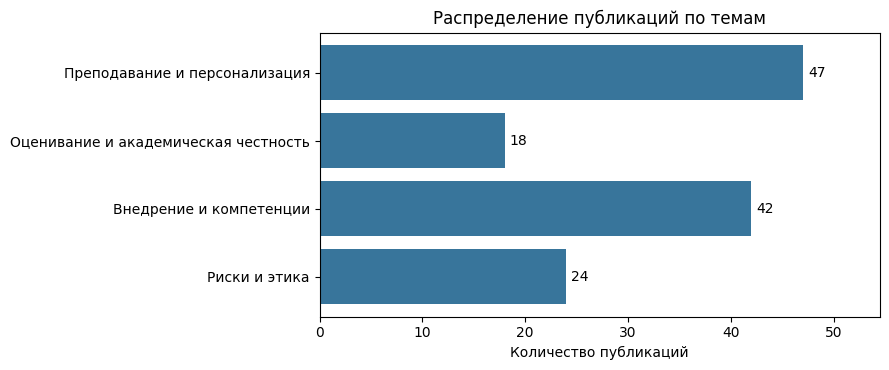

In [8]:
LABELS = ["teaching", "assessment", "adoption", "risks"]
LABEL_RU = {
    "teaching": "Преподавание и персонализация",
    "assessment": "Оценивание и академическая честность",
    "adoption": "Внедрение и компетенции",
    "risks": "Риски и этика",
}

n_before = sum(len(tokenize(text, False)) for text in articles["text"])
n_after = sum(len(text.split()) for text in articles["lemma_text"])
unique_lemmas = len(set(" ".join(articles["lemma_text"]).split()))
print(f"Токены до удаления стоп-слов: {n_before:,}".replace(",", " "))
print(f"Токены после удаления стоп-слов: {n_after:,}".replace(",", " "))
print("Уникальных лемм:", unique_lemmas)

class_counts = articles["label"].value_counts().reindex(LABELS)
display(pd.DataFrame({"Тема": [LABEL_RU[label] for label in LABELS],
                      "Число публикаций": class_counts.values}))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh([LABEL_RU[label] for label in LABELS], class_counts, color="#38759B")
ax.invert_yaxis()
ax.set(xlabel="Количество публикаций", title="Распределение публикаций по темам")
for i, n in enumerate(class_counts):
    ax.text(n + 0.5, i, str(n), va="center")
ax.set_xlim(0, max(class_counts) * 1.16)
fig.tight_layout()

plt.show()

#### Вывод по характеристике корпуса

В корпус вошли 47 статей о преподавании, 42 о внедрении ИИ, 24 о рисках и 18 об оценивании. Такое распределение показывает состав **отобранного корпуса**, но не доказывает преобладание этих тем во всей научной литературе. После удаления стоп-слов осталось 21 568 токенов и 2 743 различные леммы.

### 4.2. Частотный анализ терминов

Для отдельного слова частота определяется числом вхождений во все заголовки и аннотации. Для предметных выражений используем два показателя: **упоминания** (сколько раз встречается термин) и **документная частота** (в скольких статьях он присутствует).

\[
M(t)=\sum_{d=1}^{N} \mathrm{count}(t,d),\qquad
D(t)=\sum_{d=1}^{N} I\bigl(\mathrm{count}(t,d)>0\bigr).
\]

Термины могут пересекаться: *generative AI* также может содержать упоминание *AI*.

,Лемма,Упоминания
0,ai,828
1,student,325
2,education,318
3,study,252
4,use,238
5,teacher,191
6,genai,178
7,high,167
8,intelligence,162
9,learn,156


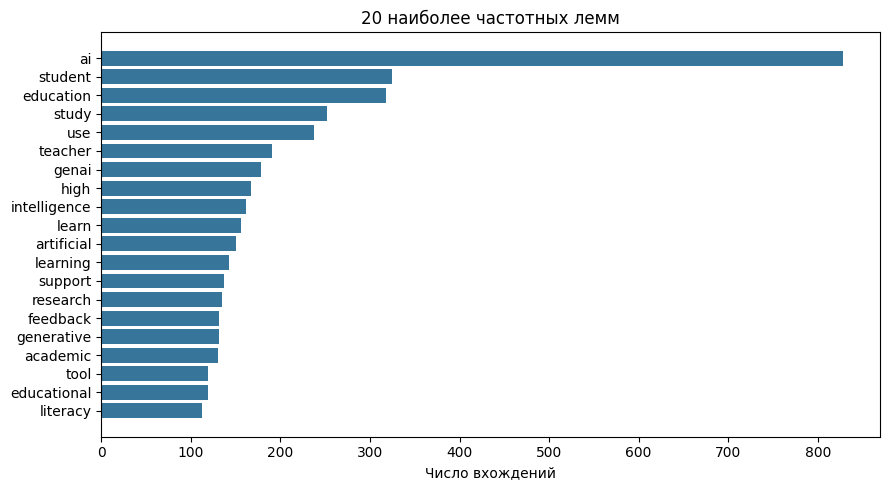

In [9]:
# Наиболее частые леммы по всему корпусу.
word_counts = Counter(word for text in articles["lemma_text"] for word in text.split())
frequent_words = pd.DataFrame(word_counts.most_common(), columns=["term", "occurrences"])
display(frequent_words.head(15).rename(columns={"term": "Лемма", "occurrences": "Упоминания"}))

fig, ax = plt.subplots(figsize=(9, 5))
top_words = frequent_words.head(20).iloc[::-1]
ax.barh(top_words["term"], top_words["occurrences"], color="#38759B")
ax.set(xlabel="Число вхождений", title="20 наиболее частотных лемм")
fig.tight_layout()

plt.show()

#### Вывод по частотности лемм

В наиболее частотных словах заметны понятия, связанные со студентами, преподавателями и использованием ИИ. Однако частотность общих слов сама по себе не показывает, в чём состоит педагогический эффект. Для предметной интерпретации далее рассчитываются частоты заранее заданных терминов.

### 4.3. Частоты тематических выражений

Для поиска ключевых терминов учтём возможные варианты их написания и сокращения. Рассчитаем число вхождений и долю публикаций, содержащих каждый термин.

,Термин,Упоминания,Статей,"Доля, %"
0,Artificial intelligence / AI,979,129,98.5
1,Generative AI / GenAI,310,66,50.4
2,LLM,46,11,8.4
3,ChatGPT,77,26,19.8
4,GPT,5,3,2.3
5,ML / Machine learning,1,1,0.8
6,DL / Deep learning,11,5,3.8
7,NLP,2,2,1.5
8,Computer vision,0,0,0.0
9,AI tutoring,6,6,4.6


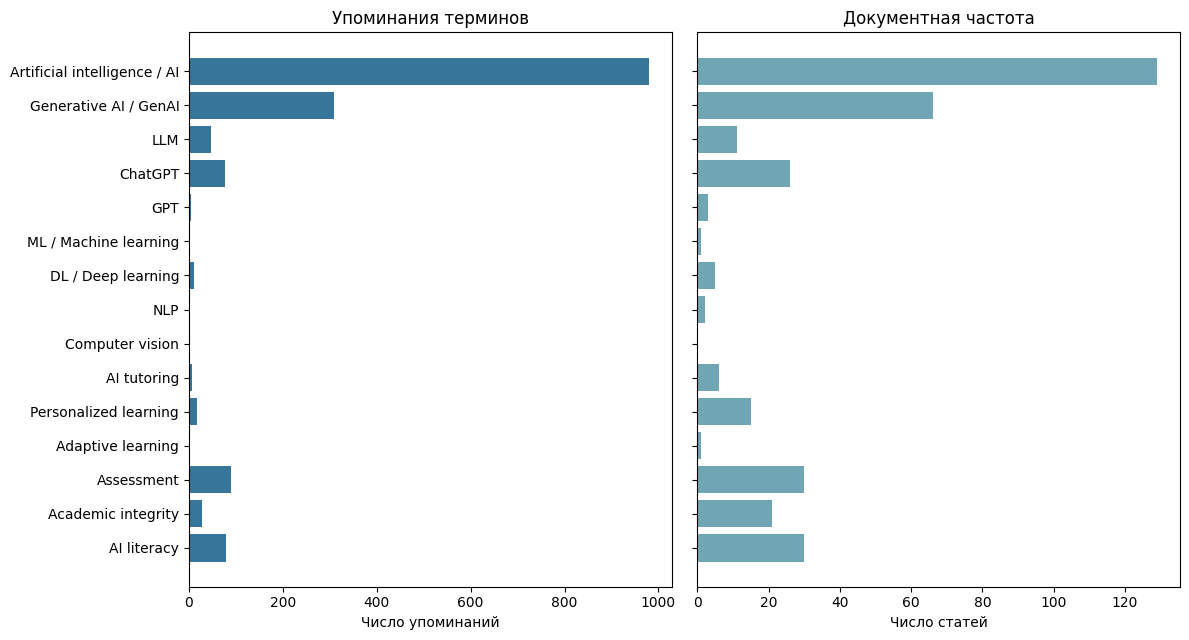

In [10]:
# Словарь тематических выражений и вариантов их написания.
TERMS={
 'Artificial intelligence / AI':r'\b(?:artificial intelligence|ai)\b',
 'Generative AI / GenAI':r'\b(?:generative (?:artificial intelligence|ai)|genai|gai)\b',
 'LLM':r'\b(?:large language models?|llms?)\b',
 'ChatGPT':r'\bchatgpt\b',
 'GPT':r'\bgpt(?:[-.]?\d+[a-z]?)?\b',
 'ML / Machine learning':r'\b(?:machine learning|ml)\b',
 'DL / Deep learning':r'\b(?:deep learning|dl)\b',
 'NLP':r'\b(?:natural language processing|nlp)\b',
 'Computer vision':r'\bcomputer vision\b',
 'AI tutoring':r'\b(?:(?:intelligent|ai(?: powered| driven)?) tutoring(?: systems?)?|ai tutors?)\b',
 'Personalized learning':r'\bpersonali[sz](?:ed|ation|ing) learning\b',
 'Adaptive learning':r'\badaptive learning\b',
 'Assessment':r'\bassessments?\b',
 'Academic integrity':r'\bacademic integrity\b',
 'AI literacy':r'\b(?:ai|artificial intelligence|genai) literacy\b',
}

cleaned_texts = articles["text"].map(lambda t: clean_text(t).replace("-", " "))
term_rows = []
for term, pattern in TERMS.items():
    counts = cleaned_texts.map(lambda text: len(re.findall(pattern, text)))
    term_rows.append({"term": term,
                      "mentions": int(counts.sum()),
                      "documents": int((counts > 0).sum()),
                      "document_percent": float((counts > 0).mean() * 100)})
term_table = pd.DataFrame(term_rows)
display(term_table.round(1).rename(columns={"term": "Термин", "mentions": "Упоминания",
                                          "documents": "Статей", "document_percent": "Доля, %"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
ordered = term_table.iloc[::-1]
axes[0].barh(ordered["term"], ordered["mentions"], color="#38759B")
axes[1].barh(ordered["term"], ordered["documents"], color="#70A5B3")
axes[0].set(xlabel="Число упоминаний", title="Упоминания терминов")
axes[1].set(xlabel="Число статей", title="Документная частота")
fig.tight_layout()

plt.show()

#### Вывод по тематическим терминам

В 129 из 131 статьи упоминается *AI* или *artificial intelligence* — высокий показатель во многом обусловлен самим поисковым запросом. *Generative AI* присутствует в 66 статьях (50,4%), *ChatGPT* — в 26 (19,8%). Темы *assessment* и *AI literacy* встречаются в 30 публикациях каждая, *academic integrity* — в 21. Эти наблюдения характеризуют **частоту обсуждения**, а не доказанную успешность внедрения технологий. Категории терминов могут пересекаться (например, AI и Generative AI), поэтому документные доли не должны суммироваться до 100%.

## 5. Выделение важных терминов методом TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) учитывает частоту слова в документе и уменьшает вес слов, встречающихся почти во всём корпусе. Для каждой статьи вычисляется вектор весов, после чего определяются слова и пары слов (**биграммы**) с наибольшим средним весом.

\[
\mathrm{idf}(t)=\ln\frac{1+N}{1+\mathrm{df}(t)}+1,\qquad
\mathrm{TFIDF}(t,d)=\mathrm{tf}(t,d)\cdot\mathrm{idf}(t),
\]

где \(N\) — число статей, \(\mathrm{df}(t)\) — число документов с термином. В `scikit-learn` результат дополнительно нормируется по L2. Униграммы и биграммы оцениваются отдельно.

Важные отдельные слова


,Термин,Средний TF-IDF
0,student,0.0665
1,genai,0.0589
2,teacher,0.0580
3,education,0.0572
4,use,0.0474
5,study,0.0445
6,high,0.0407
7,feedback,0.0404
8,review,0.0383
9,learn,0.0380


Важные биграммы


,Термин,Средний TF-IDF
0,high education,0.0523
1,artificial intelligence,0.0417
2,generative ai,0.0367
3,ai literacy,0.0361
4,self efficacy,0.0330
5,intelligence ai,0.0265
6,critical thinking,0.0254
7,generative artificial,0.0240
8,ai tool,0.0236
9,ai use,0.0199


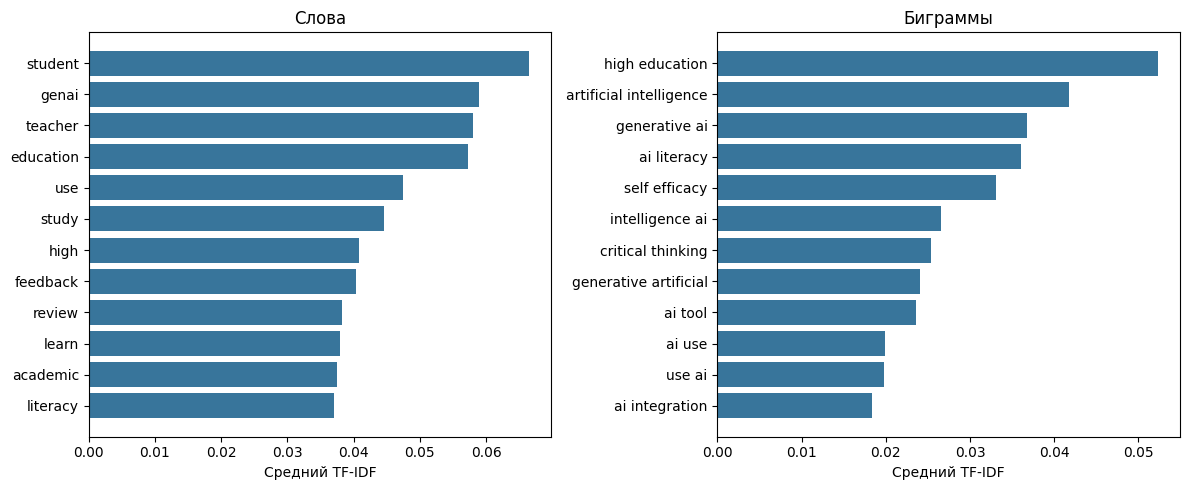

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF_PATTERN = r"(?u)\b[a-z][a-z0-9.-]+\b"
important_terms = {}
for name, ngrams in [("unigrams", (1, 1)), ("bigrams", (2, 2))]:
    vectorizer = TfidfVectorizer(lowercase=False, ngram_range=ngrams,
                                 min_df=2, max_df=0.95, token_pattern=TFIDF_PATTERN)
    matrix = vectorizer.fit_transform(articles["lemma_text"])
    mean_weights = np.asarray(matrix.mean(axis=0)).ravel()
    table = pd.DataFrame({"Термин": vectorizer.get_feature_names_out(),
                          "Средний TF-IDF": mean_weights})
    important_terms[name] = table.sort_values("Средний TF-IDF", ascending=False).reset_index(drop=True)

print("Важные отдельные слова")
display(important_terms["unigrams"].head(10).round(4))
print("Важные биграммы")
display(important_terms["bigrams"].head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, kind, title in zip(axes, ["unigrams", "bigrams"], ["Слова", "Биграммы"]):
    top = important_terms[kind].head(12).iloc[::-1]
    ax.barh(top["Термин"], top["Средний TF-IDF"], color="#38759B")
    ax.set(xlabel="Средний TF-IDF", title=title)
fig.tight_layout()

plt.show()

#### Вывод по TF-IDF

Среди заметных отдельных терминов — *student*, *genai*, *teacher*, *education*, а среди биграмм — *AI literacy*, *self efficacy*, *critical thinking* и *AI integration*. Это указывает на сочетание технологических, педагогических и организационных вопросов. Некоторые сочетания, например *intelligence ai*, формируются из названия технологии и его сокращения; такие биграммы не следует автоматически считать самостоятельными понятиями. При лемматизации *higher education* превращается в *high education*. После удаления стоп-слов биграммы могут соединять ранее несмежные слова. Веса униграмм и биграмм нормированы отдельно, поэтому их следует сравнивать внутри каждой группы, а не между группами.

### 5.1. Распределение публикаций по времени

Подсчёт публикаций по месяцам позволяет описать календарную структуру выборки. Однако данные отсортированы по цитируемости, а отдельные месяцы содержат мало статей, поэтому график **не является оценкой общего роста или спада исследований**.

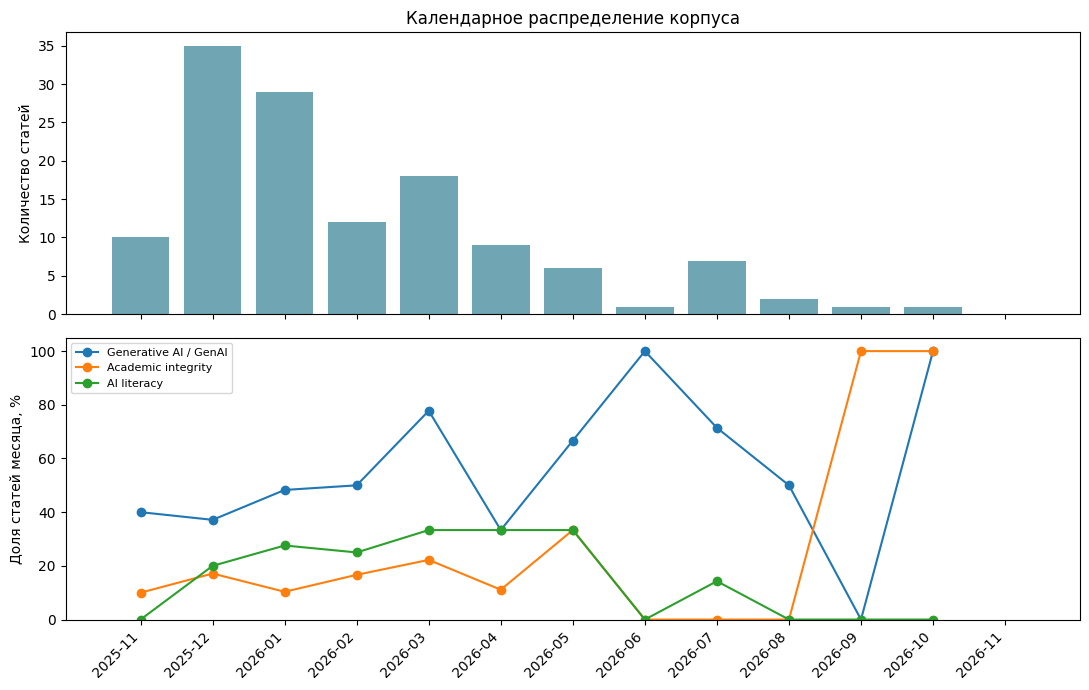

In [12]:
# Количество статей и доля публикаций с выбранными терминами по месяцам.
dates = pd.to_datetime(articles["publication_date"])
monthly_rows = []
for period in pd.period_range("2025-11", "2026-11", freq="M"):
    mask = dates.dt.to_period("M") == period
    row = {"Месяц": str(period), "Статей": int(mask.sum())}
    for term in ["Generative AI / GenAI", "Academic integrity", "AI literacy"]:
        count = cleaned_texts[mask].map(lambda t: bool(re.search(TERMS[term], t))).sum()
        row[term] = (100 * count / mask.sum()) if mask.sum() else np.nan
    monthly_rows.append(row)
monthly = pd.DataFrame(monthly_rows)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
x = np.arange(len(monthly))
axes[0].bar(x, monthly["Статей"], color="#70A5B3")
axes[0].set(ylabel="Количество статей", title="Календарное распределение корпуса")
for term in ["Generative AI / GenAI", "Academic integrity", "AI literacy"]:
    axes[1].plot(x, monthly[term], marker="o", label=term)
axes[1].set(ylabel="Доля статей месяца, %", ylim=(0, 105))
axes[1].set_xticks(x, monthly["Месяц"], rotation=45, ha="right")
axes[1].legend(fontsize=8)
fig.tight_layout()

plt.show()

#### Вывод по временному распределению

В ноябре 2025 — январе 2026 года сосредоточены 74 из 131 публикации (56,5%). Это согласуется с особенностями отбора по цитируемости и не может трактоваться как доказательство изменения интереса к ИИ. Для части поздних месяцев наблюдений слишком мало, чтобы делать выводы о динамике.

## 6. Классификация публикаций методом Naive Bayes

### 6.1. Постановка задачи классификации

Классификатор должен определить основную тему статьи по её заголовку и аннотации. Используются четыре класса: преподавание, оценивание, внедрение и риски. Алгоритм **Multinomial Naive Bayes** оценивает вероятность класса по признакам текста, предполагая их условную независимость.

\[
\hat c=\arg\max_c\left[\ln P(c)+\sum_j x_j\ln P(w_j\mid c)\right].
\]

Для объективного сравнения данные разбиваются на **обучающую** (75%) и **тестовую** (25%) части со стратификацией по темам. Подбор представления текста и параметра сглаживания \(\alpha\) выполняется по **пятикратной перекрёстной проверке на обучающих данных**. TF-IDF помещается внутрь `Pipeline`, поэтому словарь и IDF не вычисляются заранее по тестовой выборке.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

# Сравниваем константный baseline и пять конфигураций наивного Байеса.
CONFIGS = {
    "dummy":          {"vectorizer": "count", "ngrams": (1, 1), "alpha": 1,   "column": "lemma_text", "dummy": True},
    "count_uni":      {"vectorizer": "count", "ngrams": (1, 1), "alpha": 1,   "column": "lemma_text"},
    "tfidf_uni":      {"vectorizer": "tfidf", "ngrams": (1, 1), "alpha": 1,   "column": "lemma_text"},
    "tfidf_bi":       {"vectorizer": "tfidf", "ngrams": (1, 2), "alpha": 1,   "column": "lemma_text"},
    "tfidf_bi_a01":   {"vectorizer": "tfidf", "ngrams": (1, 2), "alpha": 0.1, "column": "lemma_text"},
    "tfidf_no_lemma": {"vectorizer": "tfidf", "ngrams": (1, 1), "alpha": 1,   "column": "token_text"},
}


def create_model(config):
    vector_class = CountVectorizer if config["vectorizer"] == "count" else TfidfVectorizer
    vectorizer = vector_class(ngram_range=config["ngrams"], min_df=2,
                              max_df=0.95, lowercase=False, token_pattern=TFIDF_PATTERN)
    estimator = (DummyClassifier(strategy="most_frequent") if config.get("dummy")
                 else MultinomialNB(alpha=config["alpha"]))
    return Pipeline([("vectorizer", vectorizer), ("classifier", estimator)])


all_indices = np.arange(len(articles))
train_idx, test_idx = train_test_split(all_indices, test_size=0.25,
                                       random_state=42, stratify=articles["label"])
assert not set(articles.iloc[train_idx]["id"]) & set(articles.iloc[test_idx]["id"])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Обучающая часть:", len(train_idx), "статей; тестовая:", len(test_idx))

Обучающая часть: 98 статей; тестовая: 33


#### Вывод по подготовке эксперимента

В обучение вошли 98 публикаций, в тест — 33. Разбиение фиксировано (`random_state=42`), тестовые статьи не используются при выборе признаков и гиперпараметров. Это позволяет сопоставлять конфигурации на одинаковых данных, хотя небольшой тест ограничивает точность оценки.

### 6.2. Эксперименты и сравнение моделей

Сравним простую стратегию предсказания самого частого класса (baseline), модель на частотах слов (`CountVectorizer`) и варианты на TF-IDF с униграммами, биграммами и разными коэффициентами сглаживания. В качестве главной метрики используется **macro-F1**, усредняющая F1 одинаково по всем четырём темам.

\[
\mathrm{Precision}=\frac{TP}{TP+FP},\quad
\mathrm{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2PR}{P+R}.
\]

Основную модель TF-IDF выбираем только по среднему macro-F1 перекрёстной проверки на обучающей части.

In [14]:
# Сравниваем модели только по обучающей выборке.
y = articles["label"].to_numpy()
experiments = []
for name, config in CONFIGS.items():
    X = articles[config["column"]].to_numpy()
    cv_result = cross_validate(create_model(config), X[train_idx], y[train_idx],
                               cv=cv, scoring={"accuracy": "accuracy", "f1": "f1_macro"},
                               error_score="raise")
    experiments.append({"model": name,
                        "cv_f1_macro": float(cv_result["test_f1"].mean()),
                        "cv_f1_std": float(cv_result["test_f1"].std(ddof=1))})

comparison = pd.DataFrame(experiments)
primary = comparison[comparison["model"].str.startswith("tfidf")].sort_values(
    ["cv_f1_macro", "model"], ascending=[False, False]).iloc[0]["model"]
print("Основная конфигурация TF-IDF:", primary)
display(comparison.round(4))

Основная конфигурация TF-IDF: tfidf_bi_a01


,model,cv_f1_macro,cv_f1_std
0,dummy,0.1316,0.0027
1,count_uni,0.6280,0.1504
2,tfidf_uni,0.3555,0.0321
3,tfidf_bi,0.3617,0.0212
4,tfidf_bi_a01,0.6283,0.1328
5,tfidf_no_lemma,0.3557,0.0230


#### Вывод по перекрёстной проверке

Среди TF-IDF-конфигураций наибольший средний macro-F1 (0,6283) получен при использовании униграмм и биграмм с α = 0,1. Разница с частотной моделью (0,6280) мала относительно разброса по фолдам. Выбор основной TF-IDF-конфигурации зафиксирован до обращения к тестовым данным.

### 6.3. Оценка качества на тестовой выборке

Обучим каждую конфигурацию на всех 98 обучающих статьях и оценим её на 33 отложенных публикациях. Accuracy — доля правильных ответов; Precision, Recall и F1 усредняются по четырём классам с равными весами (macro).

In [15]:
models = {}
prediction_rows = []
test_results = []
for name, config in CONFIGS.items():
    X = articles[config["column"]].to_numpy()
    model = create_model(config)
    model.fit(X[train_idx], y[train_idx])
    predicted = model.predict(X[test_idx])
    precision, recall, f1, _ = precision_recall_fscore_support(
        y[test_idx], predicted, labels=LABELS, average="macro", zero_division=0)
    test_results.append({"model": name,
                         "test_accuracy": accuracy_score(y[test_idx], predicted),
                         "test_precision_macro": precision,
                         "test_recall_macro": recall,
                         "test_f1_macro": f1})
    models[name] = model
    for idx, prediction in zip(test_idx, predicted):
        prediction_rows.append({"model": name, "id": articles.iloc[idx]["id"],
                                "title": articles.iloc[idx]["title"],
                                "true_label": y[idx], "prediction": prediction})

comparison = comparison.merge(pd.DataFrame(test_results), on="model")
comparison["selected"] = comparison["model"].eq(primary)
predictions = pd.DataFrame(prediction_rows)
display(comparison.round(4))

,model,cv_f1_macro,cv_f1_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,selected
0,dummy,0.1316,0.0027,0.3636,0.0909,0.2500,0.1333,False
1,count_uni,0.6280,0.1504,0.6970,0.7756,0.6439,0.6758,False
2,tfidf_uni,0.3555,0.0321,0.6364,0.3233,0.4564,0.3774,False
3,tfidf_bi,0.3617,0.0212,0.6061,0.3102,0.4356,0.3613,False
4,tfidf_bi_a01,0.6283,0.1328,0.5758,0.5417,0.4356,0.3994,True
5,tfidf_no_lemma,0.3557,0.0230,0.5455,0.2744,0.3902,0.3213,False


#### Вывод по сравнительному эксперименту

Среди вариантов TF-IDF по обучающей перекрёстной проверке выбран `tfidf_bi_a01` (униграммы, биграммы, \(\alpha=0{,}1\)). Его результат на тесте: **Accuracy = 0,5758, macro-F1 = 0,3994**. Вариант `count_uni` на том же тесте показал **Accuracy = 0,6970 и macro-F1 = 0,6758**, но преимущество на одном небольшом тесте не гарантирует лучшего качества на новых данных. Различие CV между `count_uni` и выбранной моделью TF-IDF мало относительно разброса по фолдам.

### 6.4. Анализ ошибок классификации

**Матрица ошибок** показывает, какие темы модель распознаёт правильно, а какие путает друг с другом. Дополнительно рассмотрим Precision, Recall и F1 для каждого класса и реальные ошибочные предсказания.

,precision,recall,f1-score,support
teaching,0.6667,0.6667,0.6667,12.0
assessment,0.0000,0.0000,0.0000,4.0
adoption,0.5000,0.9091,0.6452,11.0
risks,1.0000,0.1667,0.2857,6.0


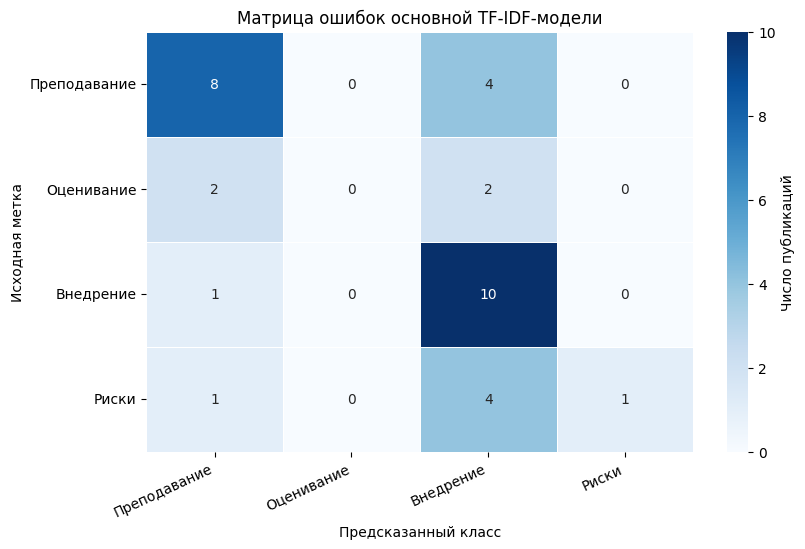

Число ошибочных классификаций: 14


,title,true_label,prediction
134,Adaptive and Personalized Learning in Higher E...,teaching,adoption
136,The EAP‐AIAS: Adapting the AI Assessment Scale...,assessment,adoption
138,Designing assessments in the generative AI era...,assessment,adoption
139,Leveraging prompt-based LLMs for automated sco...,assessment,teaching
141,AI and the digital divide in education,risks,adoption


In [16]:
primary_predictions = predictions[predictions["model"] == primary].copy()
true_labels = primary_predictions["true_label"]
pred_labels = primary_predictions["prediction"]

report = classification_report(true_labels, pred_labels, labels=LABELS,
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[LABELS, ["precision", "recall", "f1-score", "support"]]
display(per_class.round(4))

matrix = confusion_matrix(true_labels, pred_labels, labels=LABELS)
# Строки — исходные метки, столбцы — предсказания классификатора.
short_labels = ["Преподавание", "Оценивание", "Внедрение", "Риски"]
fig, ax = plt.subplots(figsize=(8.5, 5.6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", vmin=0,
            xticklabels=short_labels, yticklabels=short_labels,
            linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Число публикаций"}, ax=ax)
ax.set(xlabel="Предсказанный класс", ylabel="Исходная метка",
       title="Матрица ошибок основной TF-IDF-модели")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

mistakes = primary_predictions[primary_predictions["true_label"] != primary_predictions["prediction"]]
print("Число ошибочных классификаций:", len(mistakes))
display(mistakes[["title", "true_label", "prediction"]].head(5))

#### Вывод по качеству классификации

Основная модель верно определила 19 из 33 публикаций. Для класса «Оценивание» полнота составила **0 из 4**: классификатор относит такие статьи к другим темам. Для «Рисков» верно найдена лишь одна из шести публикаций. Следовательно, общая точность 57,6% скрывает серьёзный дисбаланс качества и модель пока не подходит для полностью автоматического распределения научных публикаций.

Например, публикация о шкале EAP-AIAS относится к оцениванию, но модель отнесла её к внедрению. Статья о цифровом неравенстве отнесена к внедрению вместо рисков. Эти ошибки иллюстрируют пересечение тематической лексики, хотя по одним предсказаниям нельзя установить точную причину ошибки.

### 6.5. Наглядное сравнение и устойчивость оценки

Сопоставление средних результатов перекрёстной проверки и тестовых результатов помогает оценить нестабильность небольшого корпуса. Для основной модели дополнительно рассчитаем приблизительные доверительные интервалы методом bootstrap при фиксированной обученной модели. На диаграмме планки ошибок показывают выборочное стандартное отклонение macro-F1 по пяти обучающим фолдам, а не доверительный интервал.

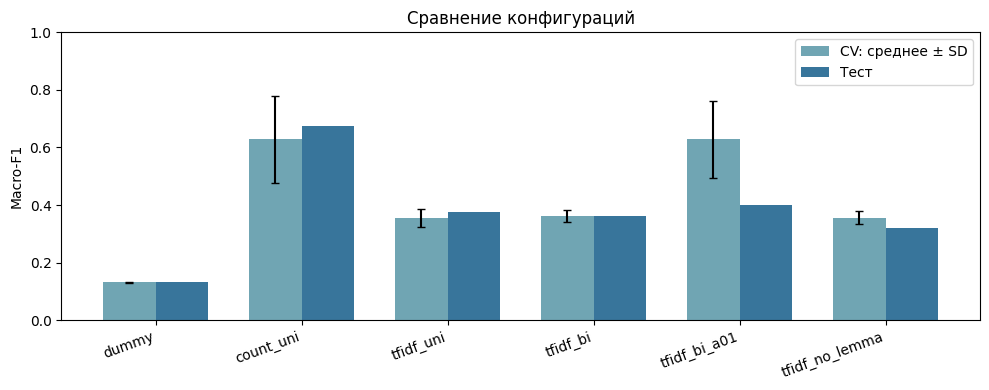

95%-й bootstrap-интервал для Accuracy: [0.455 0.697]
95%-й bootstrap-интервал для macro-F1: [0.268 0.525]


In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(comparison))
ax.bar(x - 0.18, comparison["cv_f1_macro"], 0.36, label="CV: среднее ± SD",
       yerr=comparison["cv_f1_std"], capsize=3, color="#70A5B3")
ax.bar(x + 0.18, comparison["test_f1_macro"], 0.36, label="Тест", color="#38759B")
ax.set_xticks(x, comparison["model"], rotation=20, ha="right")
ax.set(ylabel="Macro-F1", ylim=(0, 1), title="Сравнение конфигураций")
ax.legend()
fig.tight_layout()

plt.show()

# Перевыбираем пары «исходная метка — прогноз» внутри каждого класса.
rng = np.random.default_rng(42)
bootstrap_results = []
truth = true_labels.to_numpy()
pred = pred_labels.to_numpy()
for _ in range(1000):
    choice = np.concatenate([rng.choice(np.flatnonzero(truth == label),
                                         size=np.sum(truth == label), replace=True)
                             for label in LABELS])
    _, _, f1, _ = precision_recall_fscore_support(
        truth[choice], pred[choice], labels=LABELS, average="macro", zero_division=0)
    bootstrap_results.append([accuracy_score(truth[choice], pred[choice]), f1])
intervals = np.quantile(bootstrap_results, [0.025, 0.975], axis=0)
print("95%-й bootstrap-интервал для Accuracy:", np.round(intervals[:, 0], 3))
print("95%-й bootstrap-интервал для macro-F1:", np.round(intervals[:, 1], 3))

#### Вывод по устойчивости

Интервалы получены для **фиксированных прогнозов** и не учитывают возможные ошибки тематической разметки. Разброс по фолдам и небольшая тестовая выборка требуют осторожной интерпретации различий между моделями. Для повышения надёжности нужно расширить корпус, проверить разметку независимыми экспертами и повторить оценку на новых публикациях.

Для Accuracy условный 95%-й интервал составляет 0,455–0,697, для macro-F1 — 0,268–0,525. Эти интервалы характеризуют изменчивость оценки на тестовых документах при фиксированных прогнозах, а не качество на всех будущих публикациях.

## 7. Анализ тенденций применения ИИ в образовании

### 7.1. Преподавание и учебный процесс

Наиболее многочисленная тематическая группа — преподавание и персонализация (47 публикаций). Генеративный ИИ упоминается в 66 статьях. Среди важных биграмм выделяются *critical thinking* и *self efficacy*, что показывает значимость вопросов самостоятельного мышления и уверенности обучающихся в своих возможностях. При этом число упоминаний не является мерой реального улучшения учебных результатов. Например, в исследовании [9] применение чат-бота ExperiMentor сопровождалось более высокой вовлечённостью по сравнению с Excel, но статистически значимых различий в когнитивных результатах не обнаружено. Это подчёркивает необходимость отдельно измерять учебные результаты и субъективное восприятие технологии.

### 7.2. Внедрение ИИ и оценивание

К внедрению и развитию компетенций относятся 42 публикации. Термин *AI literacy* встречается в 30 документах и имеет высокий средний вес TF-IDF. Это показывает значимость подготовки преподавателей и студентов к работе с ИИ в выбранном корпусе.

Термины *assessment* и *academic integrity* встречаются соответственно в 30 и 21 публикации. Обсуждение связано с оцениванием работ, обратной связью и допустимыми способами применения ИИ. Тематический класс оценивания меньше других (18 документов); его размер не равен документной частоте термина, поскольку в каждой статье выделяется только одна основная тема. В исследовании [10] описаны ограничения детекторов ИИ-контента при проверке коротких студенческих работ и программного кода. Поэтому результаты таких детекторов не следует использовать как единственное основание для оценки академической честности.

### 7.3. Риски и ограничения

К рискам и этике отнесены 24 публикации. При внедрении ИИ необходимо учитывать конфиденциальность данных, равенство доступа и сохранение самостоятельной учебной деятельности. Целесообразно использовать ИИ для помощи в обучении, не заменяя им педагогическую оценку.

Результаты характеризуют содержание отобранных научных аннотаций. Выборка ограничена английским языком, цитируемостью и рабочей семантической разметкой. По этим данным нельзя определить распространённость ИИ во всех учебных заведениях или доказать рост его использования во времени.

## 8. Заключение

В работе реализована программа обработки научных публикаций об ИИ в образовании и проведено исследование **131 англоязычной статьи из OpenAlex**. Выполнены HTTP-получение метаданных, сохранение корпуса, токенизация, исключение стоп-слов, стемминг и лемматизация, частотный анализ, извлечение терминов по TF-IDF и классификация с помощью **Multinomial Naive Bayes**.

Анализ показал заметность генеративного ИИ, грамотности в области ИИ (*AI literacy*), проблем оценивания, обратной связи и академической честности в выбранных публикациях. На тесте основная TF-IDF-модель получила **Accuracy 0,5758** и **macro-F1 0,3994**; частотная модель Count+Naive Bayes — **0,6970** и **0,6758** соответственно. Эти показатели относятся к рабочей разметке, выполненной ИИ-ассистентом.

## 9. Список источников


1. Методические указания «РГР СИИиМО 2026», блок 1, вариант 5.
2. OpenAlex. Works API: https://api.openalex.org/works.
3. EdSurge. Terms of Service: https://www.edsurge.com/terms.
4. NLTK. Документация: https://www.nltk.org/.
5. Scikit-learn. Text feature extraction: https://scikit-learn.org/stable/modules/feature_extraction.html.
6. Scikit-learn. Naive Bayes: https://scikit-learn.org/stable/modules/naive_bayes.html.
7. Seaborn. Heatmap: https://seaborn.pydata.org/generated/seaborn.heatmap.html.
8. OpenAlex. License: https://github.com/ourresearch/openalex-docs/blob/main/license.md.
9. AI-supported data analysis boosts student motivation and reduces stress in physics education. Frontiers in Education, 2026. https://doi.org/10.3389/feduc.2026.1719670.
10. Trusting AI to detect AI? A systematic evaluation of the reliability and robustness of current AIGC detection tools for student academic work. Computers & Education, 2026. https://doi.org/10.1016/j.compedu.2026.105616.